# 04 · Model: does the satellite beat the last lab result?

**User:** a COGERH water-quality technician (or the operator of a Jaguaribe Valley water service).
**Decision:** which reservoirs to sample first, and where to start toxin testing before the next quarterly lab campaign.
**Target:** `y = 1` when cyanobacteria exceed **20,000 cells/mL** (Portaria GM/MS 888/2021: weekly cyanotoxin testing).

Today the technician's best guess is the **last lab result** (persistence). The question is whether satellite + weather + stored volume, available any week, do better on **future campaigns the model never saw**.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score
from lightgbm import LGBMClassifier
import joblib

sys.path.insert(0, str(Path.cwd().parent / "src"))
from common import PROCESSED, OUTPUTS, CYANO_THRESHOLD
from modeling import FEATURES, SATELLITE, WEATHER, WATER, SEASON, time_split, metrics, threshold_for_recall, best_f1_threshold

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
df = pd.read_csv(PROCESSED / "features.csv", parse_dates=["date"])
df["prev_log10_cyano"] = np.log10(df["prev_cyano"].clip(lower=1))
print(df.shape, "| features:", FEATURES)

(50, 42) | features: ['NDCI', 'NDTI', 'MNDWI', 'water_frac', 'tmax_7d', 'tmax_30d', 'rain_30d', 'rain_90d', 'wind_7d', 'sw_7d', 'volume_pct', 'volume_change', 'month_sin', 'month_cos', 'rainy_season']


## Time split (no shuffling across time)

Campaigns in date order: the oldest ~60% train, the next ~20% validate (model and threshold choice), the newest ~20% test, used **once** at the end.

In [2]:
df["split"] = time_split(df)
summary = df.groupby("split").agg(campaigns=("campaign", "nunique"), first=("campaign", "min"), last=("campaign", "max"),
                                  first_date=("date", "min"), last_date=("date", "max"), samples=("y", "size"),
                                  positive_share=("y", "mean")).loc[["train", "val", "test"]]
summary

,campaigns,first,last,first_date,last_date,samples,positive_share
split,,,,,,,
train,13,2016-08,2021-02,2016-08-04,2021-03-17,30,0.667
val,4,2021-05,2022-02,2021-04-06,2022-02-21,11,0.909
test,4,2022-11,2025-02,2022-11-07,2025-01-29,9,0.889


In [3]:
tr, va, te = (df[df["split"] == s].copy() for s in ["train", "val", "test"])
print("samples without a previous lab result (first visit of a reservoir):",
      {s: int(d["prev_class"].isna().sum()) for s, d in [("train", tr), ("val", va), ("test", te)]})

samples without a previous lab result (first visit of a reservoir): {'train': 0, 'val': 0, 'test': 0}


## Baselines

1. **Persistence**: predict the class of the reservoir's previous lab campaign (what the technician knows today). Its score for PR-AUC is the previous count.
2. **Majority class**: always predict "bloom".
3. **NDCI rule**: bloom if NDCI > t, with t chosen on validation to maximise F1.

Every method is scored on the same rows: samples that have a previous lab result (otherwise persistence has nothing to say).

In [4]:
va_p, te_p = va[va["prev_class"].notna()].copy(), te[te["prev_class"].notna()].copy()
t_ndci = best_f1_threshold(va_p["y"], va_p["NDCI"].values)
print(f"NDCI threshold chosen on validation: {t_ndci:.4f}")

def baselines(d):
    return {
        "Persistence (last lab result)": metrics(d["y"], d["prev_class"].astype(int), d["prev_log10_cyano"]),
        "Majority class (always bloom)": metrics(d["y"], np.ones(len(d), int), np.ones(len(d))),
        "NDCI > t": metrics(d["y"], (d["NDCI"] > t_ndci).astype(int), d["NDCI"]),
    }
pd.DataFrame(baselines(va_p)).T

NDCI threshold chosen on validation: 0.0131


,n,positives,recall,precision,F1,balanced_acc,missed_blooms (FN),false_alarms (FP),TP,TN,PR_AUC
Persistence (last lab result),11.0,10.0,0.9,0.900,0.900,0.45,1.0,1.0,9.0,0.0,0.991
Majority class (always bloom),11.0,10.0,1.0,0.909,0.952,0.50,0.0,1.0,10.0,0.0,0.909
NDCI > t,11.0,10.0,0.9,1.000,0.947,0.95,1.0,0.0,9.0,1.0,1.000


## Models

1. **Logistic regression** on standardized features, balanced class weights. The primary model: its coefficients are the explanation.
2. **LightGBM**, kept small (depth 3, 200 trees, learning rate 0.05, balanced).
3. **Logistic regression + last lab result**: the same model with the previous count (log10) added, to see if satellites add to what the technician already knows.

Missing values (a few weather windows, volume change at a reservoir's first visit) are filled with the **training** median; the scaler is also fitted on training data only.

In [5]:
def logreg():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))

models = {
    "Logistic regression": (logreg(), FEATURES),
    "LightGBM (small)": (LGBMClassifier(max_depth=3, n_estimators=200, learning_rate=0.05, class_weight="balanced",
                                        random_state=SEED, verbose=-1), FEATURES),
    "Logistic regression + last lab": (logreg(), FEATURES + ["prev_log10_cyano"]),
}
val_scores = {}
for name, (m, cols) in models.items():
    m.fit(tr[cols], tr["y"])
    val_scores[name] = m.predict_proba(va_p[cols])[:, 1]
pd.DataFrame({name: {"val PR_AUC": average_precision_score(va_p["y"], s)} for name, s in val_scores.items()}).T

,val PR_AUC
Logistic regression,0.926
LightGBM (small),0.909
Logistic regression + last lab,0.926


**Model choice (on validation only):** if logistic regression is within 0.02 PR-AUC of LightGBM, we keep logistic regression because it is easier to explain.

In [6]:
ap = {n: average_precision_score(va_p["y"], s) for n, s in val_scores.items()}
chosen = "Logistic regression" if ap["Logistic regression"] >= ap["LightGBM (small)"] - 0.02 else "LightGBM (small)"
print("chosen satellite model:", chosen, {k: round(v, 3) for k, v in ap.items()})

chosen satellite model: Logistic regression {'Logistic regression': 0.926, 'LightGBM (small)': 0.909, 'Logistic regression + last lab': 0.926}


## Decision threshold (validation)

Missing a bloom is worse than an extra sample, so the threshold is the highest one that still catches **at least 80% of blooms** on validation.

In [7]:
thresholds = {n: threshold_for_recall(va_p["y"], s, 0.80) for n, s in val_scores.items()}
print({k: round(v, 3) for k, v in thresholds.items()})

{'Logistic regression': 0.477, 'LightGBM (small)': 0.5, 'Logistic regression + last lab': 0.579}


## Test: future campaigns, used once

In [8]:
test_scores = {n: m.predict_proba(te_p[cols])[:, 1] for n, (m, cols) in models.items()}
rows = baselines(te_p)
for n, s in test_scores.items():
    rows[n] = metrics(te_p["y"], (s >= thresholds[n]).astype(int), s)
results = pd.DataFrame(rows).T
results[["n", "positives", "recall", "precision", "F1", "PR_AUC", "balanced_acc", "missed_blooms (FN)", "false_alarms (FP)", "TP", "TN"]]

,n,positives,recall,precision,F1,PR_AUC,balanced_acc,missed_blooms (FN),false_alarms (FP),TP,TN
Persistence (last lab result),9.0,8.0,0.875,0.875,0.875,0.932,0.438,1.0,1.0,7.0,0.0
Majority class (always bloom),9.0,8.0,1.000,0.889,0.941,0.889,0.500,0.0,1.0,8.0,0.0
NDCI > t,9.0,8.0,0.625,0.833,0.714,0.932,0.312,3.0,1.0,5.0,0.0
Logistic regression,9.0,8.0,0.375,1.000,0.545,1.000,0.688,5.0,0.0,3.0,1.0
LightGBM (small),9.0,8.0,1.000,0.889,0.941,0.889,0.500,0.0,1.0,8.0,0.0
Logistic regression + last lab,9.0,8.0,0.500,1.000,0.667,1.000,0.750,4.0,0.0,4.0,1.0


In [9]:
if (results["PR_AUC"] > 0.95).any():
    print("WARNING: PR-AUC > 0.95 somewhere. Check for leakage before trusting it.")
print(f"test positive share: {te_p['y'].mean():.3f}  (the PR-AUC of a random guess)")
results.to_csv(OUTPUTS / "test_results.csv")

test positive share: 0.889  (the PR-AUC of a random guess)


### How sure are these differences? (bootstrap)

We resample the test samples 1,000 times and recompute PR-AUC, to see whether the gap between the model and persistence is bigger than chance.

In [10]:
rng = np.random.default_rng(SEED)
y = te_p["y"].values
pers = te_p["prev_log10_cyano"].values
mod = test_scores[chosen]
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    if y[i].min() == y[i].max():
        continue
    diffs.append(average_precision_score(y[i], mod[i]) - average_precision_score(y[i], pers[i]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"PR-AUC({chosen}) - PR-AUC(persistence): mean {np.mean(diffs):+.3f}, 95% interval [{lo:+.3f}, {hi:+.3f}]")

PR-AUC(Logistic regression) - PR-AUC(persistence): mean +0.096, 95% interval [+0.014, +0.266]


## Explainability

Logistic regression: each bar is how much one standard deviation of that feature changes the log-odds of a bloom.

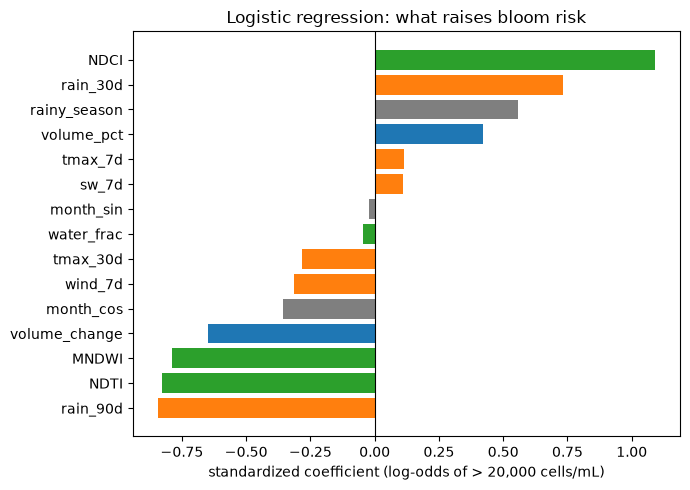

,rain_90d,NDTI,MNDWI,volume_change,month_cos,wind_7d,tmax_30d,water_frac,month_sin,sw_7d,tmax_7d,volume_pct,rainy_season,rain_30d,NDCI
coefficient,-0.844,-0.828,-0.788,-0.648,-0.357,-0.312,-0.282,-0.045,-0.023,0.112,0.115,0.422,0.559,0.732,1.091


In [11]:
lr = models["Logistic regression"][0]
coef = pd.Series(lr[-1].coef_[0], index=FEATURES).sort_values()
group = {**{f: "satellite" for f in SATELLITE}, **{f: "weather" for f in WEATHER}, **{f: "water stored" for f in WATER}, **{f: "season" for f in SEASON}}
palette = {"satellite": "tab:green", "weather": "tab:orange", "water stored": "tab:blue", "season": "tab:gray"}
colors = [palette[group[f]] for f in coef.index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(coef.index, coef.values, color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("standardized coefficient (log-odds of > 20,000 cells/mL)")
ax.set_title("Logistic regression: what raises bloom risk")
plt.tight_layout(); plt.savefig(OUTPUTS / "lr_coefficients.png", dpi=120); plt.show()
coef.round(3).to_frame("coefficient").T

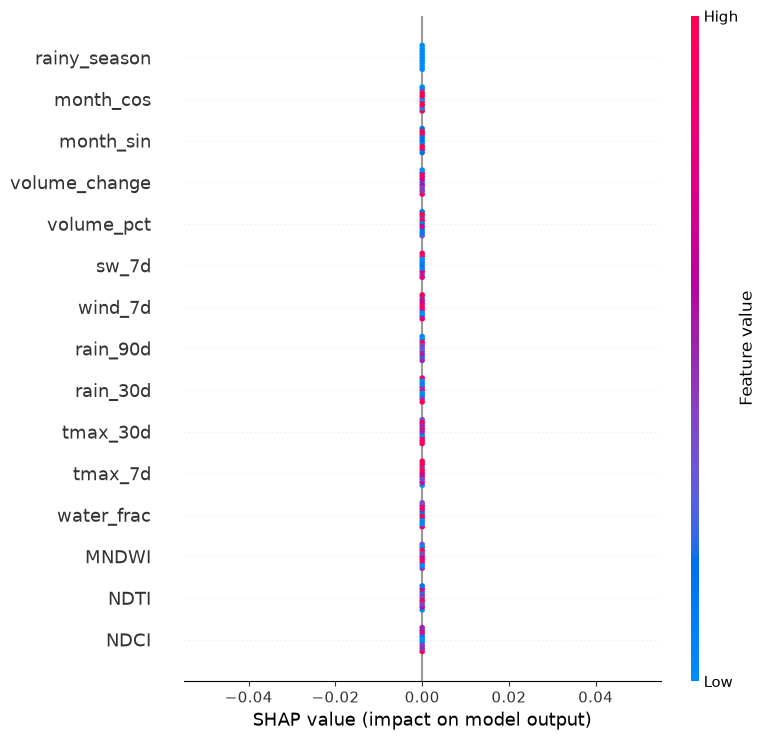

In [12]:
import shap
lgbm = models["LightGBM (small)"][0]
explainer = shap.TreeExplainer(lgbm)
sv = explainer(te_p[FEATURES])
shap.summary_plot(sv, te_p[FEATURES], show=False)
plt.tight_layout(); plt.savefig(OUTPUTS / "lgbm_shap_summary.png", dpi=110); plt.show()

## Our own questions

1. **Drought:** does the model work as well when the reservoir is below 20% of its volume?
2. **Unseen reservoirs:** train on some reservoirs and test on others (5 folds grouped by reservoir).
3. **Date gap:** do results change if we keep only samples where the image is within 2 days of the lab visit?

In [13]:
s_test = test_scores[chosen]
pred = (s_test >= thresholds[chosen]).astype(int)
low = te_p["volume_pct"] < 20
q1 = pd.DataFrame({
    "volume < 20%": metrics(te_p["y"][low], pred[low.values], s_test[low.values]),
    "volume >= 20%": metrics(te_p["y"][~low], pred[~low.values], s_test[~low.values]),
}).T[["n", "positives", "recall", "precision", "missed_blooms (FN)", "false_alarms (FP)"]]
q1

,n,positives,recall,precision,missed_blooms (FN),false_alarms (FP)
volume < 20%,3.0,3.0,0.333,1.0,2.0,0.0
volume >= 20%,6.0,5.0,0.400,1.0,3.0,0.0


In [14]:
gkf = GroupKFold(n_splits=5)
rows = []
for k, (i_tr, i_te) in enumerate(gkf.split(df, df["y"], groups=df["reservoir"])):
    a, b = df.iloc[i_tr], df.iloc[i_te]
    m = logreg().fit(a[FEATURES], a["y"])
    bp = b[b["prev_class"].notna()]
    rows.append({"fold": k, "test_reservoirs": b["reservoir"].nunique(), "n": len(bp),
                 "PR_AUC model": average_precision_score(bp["y"], m.predict_proba(bp[FEATURES])[:, 1]),
                 "PR_AUC persistence": average_precision_score(bp["y"], bp["prev_log10_cyano"])})
q2 = pd.DataFrame(rows)
print(q2.round(3).to_string(index=False))
print("mean:", q2[["PR_AUC model", "PR_AUC persistence"]].mean().round(3).to_dict())

 fold  test_reservoirs  n  PR_AUC model  PR_AUC persistence
    0                6 10         0.654               0.938
    1                6 10         0.733               0.871
    2                6 10         1.000               0.963
    3                7 10         0.947               0.989
    4                7 10         0.704               0.739
mean: {'PR_AUC model': 0.808, 'PR_AUC persistence': 0.9}


In [15]:
near = (te_p["day_gap"] <= 2).values
q3 = pd.DataFrame({
    "all test samples": metrics(te_p["y"], pred, s_test),
    "image within 2 days": metrics(te_p["y"][near], pred[near], s_test[near]),
}).T[["n", "recall", "precision", "PR_AUC"]]
q3

,n,recall,precision,PR_AUC
all test samples,9.0,0.375,1.0,1.0
image within 2 days,6.0,0.200,1.0,1.0


## Where it fails

The 5 worst missed blooms (lowest predicted risk among real blooms) and the 5 worst false alarms (highest risk among clean samples) in the test campaigns.

In [16]:
te_p["risk"] = s_test
cols_show = ["reservoir", "date", "img_date", "day_gap", "cyano", "chla", "risk", "NDCI", "NDTI", "water_frac", "volume_pct", "n_water_px"]
fn = te_p[(te_p["y"] == 1)].nsmallest(5, "risk")[cols_show]
fp = te_p[(te_p["y"] == 0)].nlargest(5, "risk")[cols_show]
print("Missed blooms:"); display(fn)
print("False alarms:"); display(fp)

Missed blooms:


,reservoir,date,img_date,day_gap,cyano,chla,risk,NDCI,NDTI,water_frac,volume_pct,n_water_px
43,santa maria,2024-01-29,2024-01-28,1.0,139222.0,NaN,0.227,-0.010,-0.109,0.422,17.9,111.0
46,joaquim tavora,2024-07-22,2024-07-21,1.0,329176.0,NaN,0.258,-0.027,-0.130,0.468,30.1,969.0
42,cedro,2024-01-29,2024-02-02,4.0,453060.0,NaN,0.334,0.149,-0.097,0.541,0.7,1207.0
45,pau preto,2024-07-17,2024-07-16,1.0,23537.0,10.96,0.386,-0.051,-0.168,0.048,89.6,95.0
44,trussu,2024-07-10,2024-07-11,1.0,71380.0,NaN,0.409,0.039,-0.137,0.544,58.6,1427.0


False alarms:


,reservoir,date,img_date,day_gap,cyano,chla,risk,NDCI,NDTI,water_frac,volume_pct,n_water_px
47,cipoada,2024-08-01,2024-07-31,1.0,2035.0,NaN,0.123,0.038,-0.017,0.475,31.7,1280.0


## Save the chosen model for the risk map

In [17]:
final_name = chosen
final_model = models[final_name][0]
joblib.dump({"name": final_name, "model": final_model, "features": FEATURES, "threshold": thresholds[final_name],
             "train_campaigns": sorted(tr["campaign"].unique())}, OUTPUTS / "model.joblib")
print("saved", final_name, "threshold", round(thresholds[final_name], 3))

saved Logistic regression threshold 0.477
